# Intro to NLP

## Part 1: Text Classification

We learn the building blocks of Natural Language Processing (NLP) by solving one complete task.

**The task.** The input is a movie review, a string of text.
The output is one number $\hat p$, the model's estimated probability that the review is positive.
The labels come from IMDb: each review is marked 1 (positive) or 0 (negative).

**The model.** Text has no natural numeric variables, so each word gets a vector of 64 numbers,
its **embedding**. These numbers are not given; they are learned along with everything else.
The model averages the word vectors of a review, passes the average through one hidden layer,
and turns the result into a probability.

**The parameter count, 1,284,225.** It comes straight from the model's pieces:

| Piece | Shape | Count |
|---|---|---|
| Embedding table $E$ (one 64-vector per word) | $64\times20{,}000$ | 1,280,000 |
| Hidden-layer weights $W$ | $64\times64$ | 4,096 |
| Hidden-layer bias $b$ | $64$ | 64 |
| Output weights $v$ | $64$ | 64 |
| Output bias $c$ | $1$ | 1 |
| **Total** | | **1,284,225** |

About 99.7% of the parameters are in the embedding table.
That is typical in NLP: most of what the model knows lives in its word vectors.

**One limitation to keep in mind.** The model averages the word vectors of a review,
so it ignores word order.

**Roadmap.** The sections follow the order of the computation:

1. Text → tokens → IDs: turn a string into integers.
2. IDs → vectors → average → hidden layer → probability: the *forward pass*.
3. Loss → gradients → update: how the parameters learn.
4. Train on 22,411 reviews, evaluate on reviews the model never saw, and inspect what it learned.
5. Two experiments on the data: how accuracy changes with the number of training reviews, and with wrong labels.

## Julia setup

Select the **Julia 1.12** kernel and run the cells in order.

- Data: IMDb reviews in `reference/datasets/imdb/`.
- Functions: `src/IntroNLP/`, loaded by the setup cell.

The model fits on a CPU in under a minute. The experiments at the end refit it many times (about 10 and 13 minutes); their saved results in `output/nlp_course/` load automatically.

In [1]:
using Pkg
function find_project_root(start_dir=pwd())
    dir=abspath(start_dir)
    while !isfile(joinpath(dir,"Project.toml"))
        parent=dirname(dir)
        parent==dir && error("Could not find Project.toml from $(start_dir)")
        dir=parent
    end
    dir
end
project_root=find_project_root()
if Base.active_project()===nothing || normpath(Base.active_project())!=joinpath(project_root,"Project.toml")
    Pkg.activate(project_root)
end
ENV["GKSwstype"]="100"
using Flux, Random, Statistics, LinearAlgebra, SparseArrays, Serialization, Printf, Plots, LaTeXStrings
BLAS.set_num_threads(1)
include(joinpath(project_root,"src","IntroNLP","IntroNLP.jl"))

IMDB_DIR=joinpath(project_root,"reference","datasets","imdb")
RESULTS=joinpath(project_root,"output","nlp_course")
mkpath(RESULTS)
println("Julia ",VERSION," · Flux ",pkgversion(Flux))

Julia 

1.12.4 · Flux 0.16.10


## 1. The task and the data

### 1.1 What we observe and what we predict

Each observation is one movie review: its text $s_n$ and its label

$$y_n=\begin{cases}1&\text{positive review},\\0&\text{negative review},\end{cases}$$

where $n=1,\ldots,N$ indexes the reviews.

The model is a function with trainable parameters $\theta$.
It maps the text to a probability:

$$\hat p_n=f_\theta(s_n)\in(0,1),\qquad \hat p_n\approx P(y_n=1\mid s_n).$$

We predict "positive" when $\hat p_n\geq0.5$.
The label is given for the **whole review**; no individual word is labeled.
The model must learn by itself which words matter.

A neural network works with numbers, not text.
Figure 1 shows how this notebook turns a review into a probability.
Steps in **teal** are fixed rules; steps in **amber** contain trainable parameters.
The sections below explain each step in order.

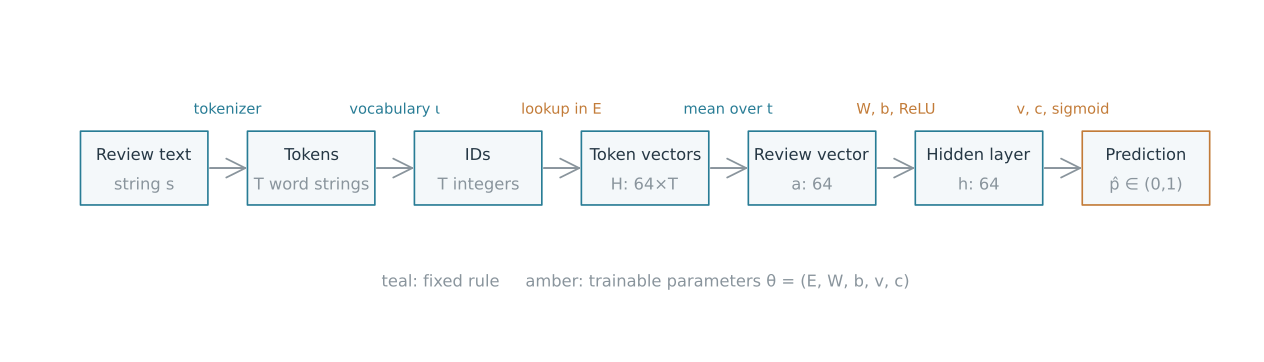

In [2]:
pipeline_diagram()

*Figure 1. The path from a review string to a probability. Only the amber operations are learned; tokenization, ID lookup, and averaging are fixed rules.*

### 1.2 Tokenize: split the text into units

A **tokenizer** converts a string into numbers in two steps:

1. **Split** the string into units called **tokens**.
2. **Convert** each token into an integer **ID** by looking it up in a fixed list, the **vocabulary**.

There are three common ways to split text (Figure 2):

| Split by | Tokens are | Advantage | Disadvantage |
|---|---|---|---|
| **Word** | whole words | each token has a complete meaning | large vocabulary; unseen words become unknown; `movie` and `movies` are unrelated tokens |
| **Character** | single letters | tiny vocabulary, no unknown tokens | long sequences; one letter carries little meaning |
| **Subword** | frequent words whole, rare words in pieces | balances the two | the split rules must first be estimated from a corpus |

**This notebook uses every word as a token.** It is the simplest choice,
and every result later in the notebook can be read as whole words.

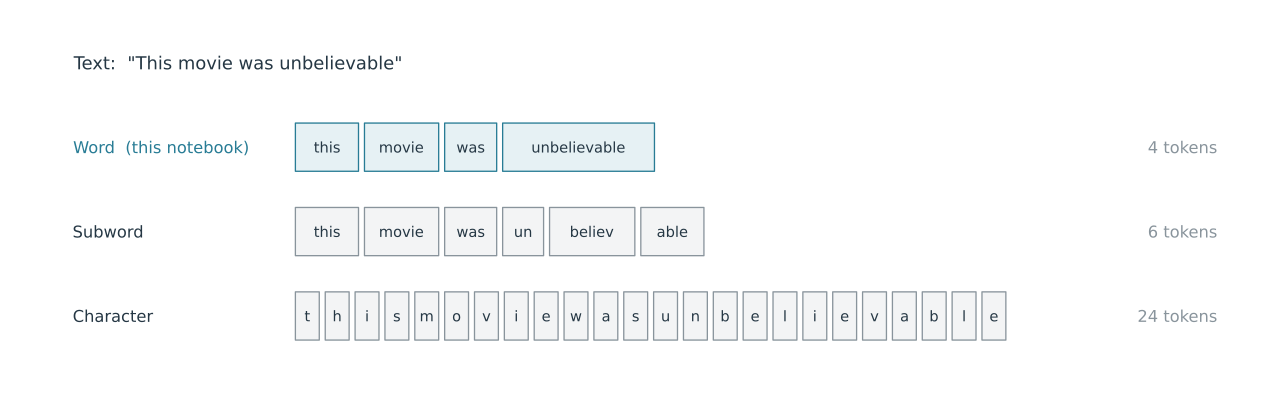

In [3]:
tokenizer_diagram()

*Figure 2. One sentence, three ways to split it. Word tokens are few and meaningful; character tokens are many and individually uninformative; subword tokens lie in between. The subword split is illustrative: real splits depend on the statistics used to build that tokenizer.*

Our word tokenizer applies three fixed rules:

1. Remove HTML tags such as `<br />`, which IMDb reviews use for line breaks.
2. Lowercase everything, so `Film` and `film` are the same token.
3. Keep runs of the letters a–z, allowing one apostrophe part, so `don't` stays whole.
   Punctuation and digits are dropped; words such as `not` are kept.

Rule 3 only knows the letters a–z, so an accented word such as `féminin` splits into `f` and `minin`.
The real review below shows this.
These rules are written by hand and never change: **the tokenizer is not trained.**

`word_tokens` (in `src/IntroNLP/tokenizer.jl`) applies the three rules.
`word_ids` then converts each token into its ID, using ID 1 for any word outside the vocabulary.
The cell below tokenizes a short example.

In [4]:
example="This movie was <br />UNBELIEVABLE... I didn't expect it to be 10/10!"
println(word_tokens(example))

["this", "movie", "was", "unbelievable", "i", "didn't", "expect", "it", "to", "be"]


Build a vocabulary $\mathcal V$ using **training text only**. Its size is
$V=|\mathcal V|=20{,}000$, including the special entry `<unk>`.
The vocabulary map $\iota:\mathcal V\to\{1,\ldots,V\}$ assigns each entry an integer ID.
`<unk>` stands for *unknown*: every word outside the vocabulary maps to its ID, 1.
The vocabulary is built once, by counting words; no gradient or loss is involved.

For one review, the transformations are

$$s\ \xrightarrow{\text{tokenizer}}\ (w_1,\ldots,w_T)
  \ \xrightarrow{\iota}\ (x_1,\ldots,x_T),\qquad x_t=\iota(w_t).$$

$T$ is this review's number of tokens, $t$ is a token position,
$w_t$ is the token string, and $x_t$ is its integer ID.
**An ID is a table address**; adding two IDs or comparing their numerical distance
does not measure the words' meanings.

### 1.3 Prepare the IMDb splits

[IMDb](https://huggingface.co/datasets/stanfordnlp/imdb) supplies 25,000 labeled training
reviews and 25,000 labeled test reviews. Our local preparation groups identical normalized
texts, retains one same-label copy, and discards conflicting-label groups.
It reserves a stratified 10% of the remaining training pool for validation.
It also removes test duplicates and exact overlaps with the original training pool.

| Prepared split | Reviews | Purpose |
|---|---:|---|
| Training | 22,411 | Build the vocabulary and update parameters |
| Validation | 2,490 | Choose the stopping checkpoint |
| Test | 24,675 | Evaluate the selected model |

The supplied TSVs contain source row IDs, labels, and hex-encoded UTF-8 text.
Source cards and hashes accompany the data; the dataset card lists the license as `other`.
This documented filtered split is not an unmodified leaderboard benchmark.

The code chooses the **first training review in source order with 80–160 tokens** for the
calculation walkthrough. This is one observation from the full project, chosen by length,
not by whether the model predicts it correctly. Every token in that review is used.

In [5]:
imdb=prepare_imdb(IMDB_DIR)
for name in (:training,:validation,:test)
    data=getproperty(imdb,name)
    @printf("%-11s %6d reviews | positive %.1f%%\n",string(name),length(data.rows),100mean(data.y))
end

V_review=length(imdb.vocab)
@assert V_review==20000
# Choose by length in source order, never by the model's prediction.
trace_at=findfirst(i->80<=length(imdb.training.ids[i])<=160,
    eachindex(imdb.training.rows))
trace_row=imdb.training.rows[trace_at]
trace_ids=imdb.training.ids[trace_at]
trace_tokens=word_tokens(trace_row.text)
T_review=length(trace_ids)
@printf("\nTraining-source row %d | %d tokens | supplied label %d\n",
    trace_row.id,T_review,trace_row.y)
excerpt=join(first(split(replace(trace_row.text,r"<[^>]*>"=>" ")),30)," ")
println("Review excerpt (all tokens are still used): ",excerpt," …")
println("\nFirst 16 tokens and vocabulary IDs (the model uses all tokens):")
for t in 1:16
    @printf("%2d  %-18s  ID %5d  table entry: %s\n",
        t,trace_tokens[t],trace_ids[t],imdb.vocab[trace_ids[t]])
end

training     22411 reviews | positive 50.1%
validation    2490 reviews | positive 50.1%
test         24675 reviews | positive 50.3%

Training-source row 3 | 115 tokens | supplied label 0
Review excerpt (all tokens are still used): This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead. The film has two strong elements and those are, (1) the realistic …

First 16 tokens and vocabulary IDs (the model uses all tokens):


 1  this                ID    11  table entry: this
 2  film                ID    19  table entry: film
 3  was                 ID    13  table entry: was
 4  probably            ID   238  table entry: probably
 5  inspired            ID  1565  table entry: inspired
 6  by                  ID    31  table entry: by
 7  godard's            ID 17441  table entry: godard's
 8  masculin            ID     1  table entry: <unk>
 9  f                   ID  1066  table entry: f
10  minin               ID     1  table entry: <unk>
11  and                 ID     3  table entry: and
12  i                   ID    10  table entry: i
13  urge                ID  4286  table entry: urge
14  you                 ID    22  table entry: you
15  to                  ID     6  table entry: to
16  see                 ID    64  table entry: see


### 1.4 How much text becomes `<unk>`?

Two different counts matter here:

- A **word type** is a distinct word. `movie` is one type, however often it appears.
- A **word occurrence** is one appearance of a word in a review.

The vocabulary drops most word *types*, but those types are names, typos, and rare words
that appear once or twice. Common types such as `the` and `movie` appear hundreds of thousands
of times. So the share of *occurrences* that becomes `<unk>` is small.
Figure 3 sorts the training word types from most to least frequent and shows what share
of all occurrences the most frequent $k$ types cover.

Training word types: 76193 | kept in the vocabulary: 19999 (26%)
Types that appear only once: 29137 (38% of all types)


Training occurrences: 5208530 | covered: 97.5% | become <unk>: 2.5%


Test occurrences that become <unk>: 3.3%

  the       appears  301992 times in training
  movie     appears   39246 times in training
  great     appears    8086 times in training
  boring    appears    1611 times in training


  masculin  appears       1 times in training


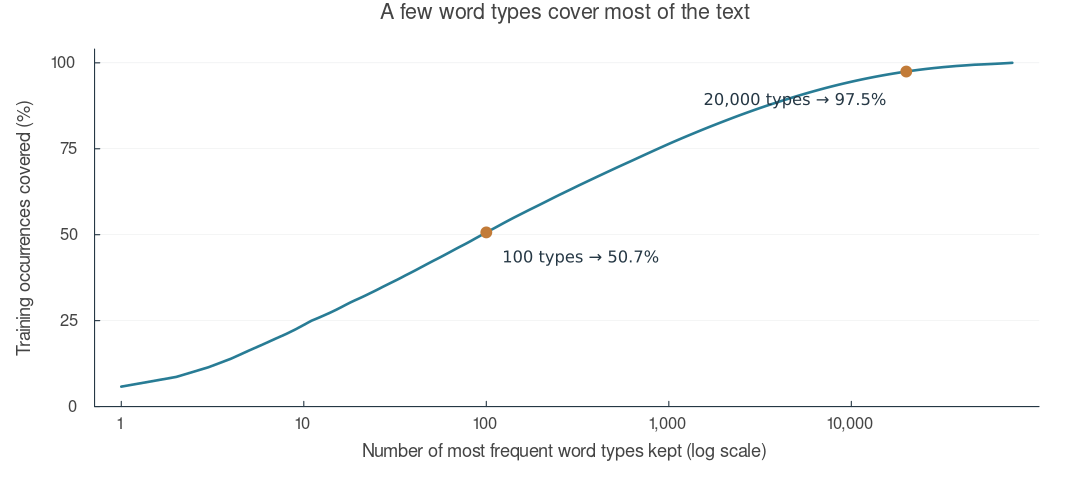

In [6]:
train_counts=count_words(imdb.training.rows)
freqs=sort(collect(values(train_counts));rev=true)
coverage=cumsum(freqs)./sum(freqs)
n_types,kept=length(freqs),V_review-1
once=count(==(1),freqs)
@printf("Training word types: %d | kept in the vocabulary: %d (%.0f%%)\n",n_types,kept,100kept/n_types)
@printf("Types that appear only once: %d (%.0f%% of all types)\n",once,100once/n_types)
@printf("Training occurrences: %d | covered: %.1f%% | become <unk>: %.1f%%\n",
    sum(freqs),100coverage[kept],100(1-coverage[kept]))
test_unk=sum(count(==(1),ids) for ids in imdb.test.ids)/sum(length,imdb.test.ids)
@printf("Test occurrences that become <unk>: %.1f%%\n\n",100test_unk)
for w in ["the","movie","great","boring","masculin"]
    @printf("  %-9s appears %7d times in training\n",w,get(train_counts,w,0))
end
coverage_plot(freqs,kept)

*Figure 3. Coverage of the training text by the most frequent word types. The 100 most common types already cover about half of all occurrences; the 20,000-type vocabulary covers nearly all of them, although it keeps only a quarter of the types.*

## 2. Define the network, one operation at a time

### 2.1 The embedding table is a parameter matrix

Choose an embedding dimension $d=64$. Each vocabulary entry has one trainable vector
$e_j\in\mathbb R^{64}$, where $j\in\{1,\ldots,20{,}000\}$ is a vocabulary ID.
Stack these vectors as **columns**:

$$E=\begin{bmatrix}e_1&e_2&\cdots&e_V\end{bmatrix}
  \in\mathbb R^{d\times V}=\mathbb R^{64\times20{,}000}.$$

The scalar $E_{rj}$ is coordinate $r$ of vocabulary entry $j$.
Thus $E[:,j]=e_j$, where the colon means “all coordinates.”
The table contains $64\times20{,}000=1{,}280{,}000$ trainable numbers.

Before training, every entry is an independent random draw:

$$E_{rj}\overset{\text{iid}}{\sim}\mathcal N\!\left(0,\,0.1^2\right),\qquad r=1,\ldots,64,\quad j=1,\ldots,20{,}000.$$

Random values make every word's vector different from the start; if all entries were zero,
every gradient reaching $E$ would also be zero and nothing would be learned.
Training changes the values; it does not change the chosen dimension $d$. A coordinate is not assigned a meaning such as “emotion” or “noun.”
Predictive information can be spread across many coordinates.
The remaining parameter names are the hidden-layer weights $W\in\mathbb R^{64\times64}$,
hidden bias $b\in\mathbb R^{64}$, output weights $v\in\mathbb R^{64}$, and output bias
$c\in\mathbb R$. They are also initialized at random, with biases at zero:

$$W_{kr}\overset{\text{iid}}{\sim}\mathcal N\!\left(0,\,\tfrac{2}{64}\right),\qquad
  v_k\overset{\text{iid}}{\sim}\mathcal N\!\left(0,\,\tfrac{1}{64}\right),\qquad
  b=0,\qquad c=0.$$

The following cell draws all of them once, with a fixed random seed so every run starts from the same values.
The next two subsections derive their operations.

In [7]:
classifier_initial=review_model(V_review;d=64,hidden=64)
@printf("Embedding table E: %s = %d trainable entries\n",
    string(size(classifier_initial.E)),length(classifier_initial.E))
@assert sum(length,values(classifier_initial))==1284225

Embedding table E: (64, 20000) = 1280000 trainable entries


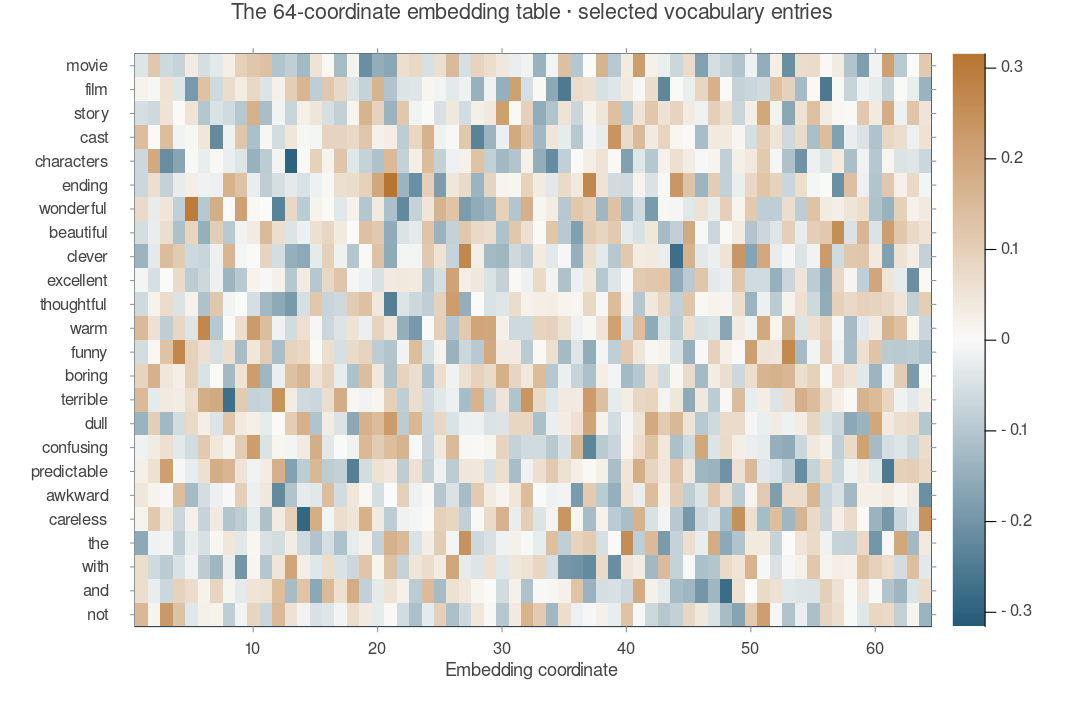

In [8]:
shown_words=["movie","film","story","cast","characters","ending","wonderful","beautiful",
    "clever","excellent","thoughtful","warm","funny","boring","terrible","dull",
    "confusing","predictable","awkward","careless","the","with","and","not"]
shown_words=filter(w->haskey(imdb.lookup,w),shown_words)
shown_ids=[imdb.lookup[w] for w in shown_words]
matrix_panel(classifier_initial.E[:,shown_ids]';rowlabels=shown_words,
    title="The 64-coordinate embedding table · selected vocabulary entries",
    xlabel="Embedding coordinate") |> p->plot(p;size=(980,650))

*Figure 4. Selected entries from the actual 64 × 20,000 initial table. All 64 coordinates are shown; the displayed words are only a view into the full vocabulary.*

### 2.2 Look up one vector for every token position

For the selected review, token position $t$ contains vocabulary ID $x_t$.
Define its looked-up vector as $\tilde e_t=e_{x_t}=E[:,x_t]$.
Collect the vectors in a new matrix:

$$H=\begin{bmatrix}\tilde e_1&\cdots&\tilde e_T\end{bmatrix}
  \in\mathbb R^{64\times T},\qquad H_{rt}=E_{r,x_t}.$$

$E$ stores a vector for **every vocabulary entry**.
$H$ contains the vectors selected by **this review**, in token order.
If the same token ID appears twice, two columns of $H$ refer to the same column of $E$.
The lookup is not a separate learned transformation: the entries of $E$ are the parameters.
Equivalently, let $o_j\in\mathbb R^V$ be the **one-hot vector** with a 1 in entry $j$ and zeros elsewhere.
Then $E\,o_{x_t}=E[:,x_t]$: multiplying by a one-hot vector picks one column.
Libraries implement the lookup as indexing because it gives the same result without forming $o_j$.

In [9]:
trace_H=classifier_initial.E[:,trace_ids]
@assert size(trace_H)==(64,T_review)
println("H has shape ",size(trace_H),": 64 coordinates × ",T_review," token positions.")
println("First five coordinates of the first three token vectors:")
for t in 1:3
    @printf("%-12s ID=%5d  %s\n",trace_tokens[t],trace_ids[t],
        string(round.(trace_H[1:5,t];digits=4)))
end

H has shape (64, 115): 64 coordinates × 115 token positions.
First five coordinates of the first three token vectors:
this         ID=   11  Float32[0.149, -0.0328, 0.063, -0.0313, -0.0949]


film         ID=   19  Float32[0.0198, -0.0067, 0.0576, -0.039, -0.1927]
was          ID=   13  Float32[0.0585, 0.0074, 0.0966, 0.059, 0.0543]


### 2.3 Mean pooling: average across tokens, coordinate by coordinate

The neural classifier needs one fixed-length vector, although reviews have different $T$.
We choose **mean pooling**. Define the review vector $a\in\mathbb R^{64}$ by

$$a=\frac{1}{T}\sum_{t=1}^T\tilde e_t
    =\frac{1}{T}\sum_{t=1}^T E[:,x_t]
    =\frac{1}{T}H\mathbf1_T.$$

Here $\mathbf1_T$ is a $T$-vector of ones. Written one coordinate at a time,

$$a_r=\frac{E_{r,x_1}+E_{r,x_2}+\cdots+E_{r,x_T}}{T},
  \qquad r=1,\ldots,64.$$

So $a_1$ averages coordinate 1 over all tokens, $a_2$ averages coordinate 2, and so on.
We average **along the token-position axis**, keeping 64 separate coordinates.
Mean pooling is a modeling choice; it is not part of the definition of an embedding.

Repeated words can be counted instead of looked up repeatedly. For vocabulary ID $j$, define

$$n_j=\sum_{t=1}^T\mathbf1\{x_t=j\},\qquad
  f_j=\frac{n_j}{T},\qquad
  f=(f_1,\ldots,f_V)^\top\in\mathbb R^V.$$

$n_j$ is a count and $f_j$ is the fraction of review tokens with ID $j$.
Regrouping the same sum gives

$$a=\sum_{j=1}^V f_j e_j=Ef,\qquad \sum_{j=1}^V f_j=1.$$

For a batch of $B$ reviews, place their frequency vectors in
$F=[f^{(1)},\ldots,f^{(B)}]\in\mathbb R^{V\times B}$.
Then $EF\in\mathbb R^{64\times B}$ contains all their means.
$F$ is observed input data, not a trainable matrix. Most entries are zero, so sparse storage
makes this exact calculation efficient without discarding any words.

Because $a$ depends on a review only through its word frequencies $f$, this representation is a
**bag of words**: it records which words occur and how often, not their order.

In [10]:
imdb=merge(imdb,(training=add_frequencies(imdb.training,V_review),
    validation=add_frequencies(imdb.validation,V_review),
    test=add_frequencies(imdb.test,V_review)))
trace_f=imdb.training.F[:,trace_at:trace_at]
trace_mean=vec(mean(trace_H;dims=2))
@assert trace_mean≈vec(classifier_initial.E*trace_f)
@assert isapprox(sum(trace_f),1f0;atol=1f-6)
coordinate=7
@printf("Coordinate %d: sum across %d tokens = %.6f; divide by %d → %.6f\n",
    coordinate,T_review,sum(trace_H[coordinate,:]),T_review,trace_mean[coordinate])
@printf("f shape %s | E*f shape %s | all training means: 64 × %d\n",
    string(size(trace_f)),string(size(classifier_initial.E*trace_f)),length(imdb.training.rows))

Coordinate 7: sum across 115 tokens = -0.687907; divide by 115 → -0.005982
f shape (20000, 1) | E*f shape (64, 1) | all training means: 64 × 22411


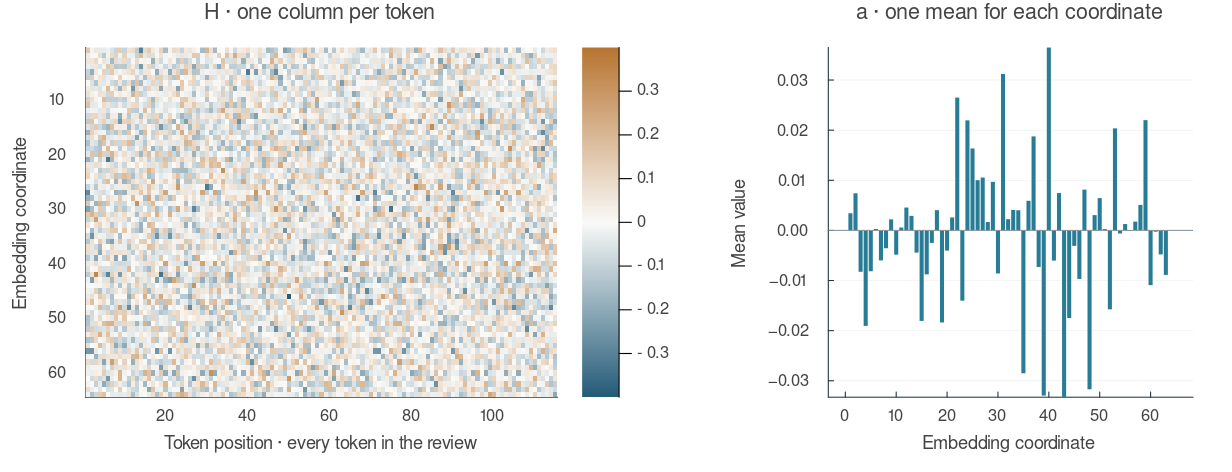

In [11]:
pooling_plot(trace_H,trace_mean)

*Figure 5. Left: all token vectors of the selected real review. Averaging across its columns produces the 64 values on the right. The numerical check confirms that lookup-and-average and E times the frequency vector are the same operation.*

### 2.4 Transform the review vector with a hidden layer

Choose $m=64$ hidden units. Define a trainable weight matrix $W\in\mathbb R^{m\times d}$
and bias vector $b\in\mathbb R^m$. First compute the pre-activation vector $u$:

$$u=Wa+b\in\mathbb R^{64},\qquad
  u_k=\sum_{r=1}^{64}W_{kr}a_r+b_k,\quad k=1,\ldots,64.$$

Each hidden unit has its own weighted combination of all input coordinates.
Next apply the rectified linear unit (ReLU) to each coordinate:

$$h=\operatorname{ReLU}(u),\qquad h_k=\max(0,u_k).$$

$h\in\mathbb R^{64}$ is the hidden activation vector.
$d$ and $m$ are independent design choices; both happen to equal 64 here.
The nonlinearity lets the model learn a more flexible function than a single linear score.

### 2.5 Convert hidden activations into one probability

Define a trainable output vector $v\in\mathbb R^{64}$ and scalar bias $c\in\mathbb R$.
The output **logit** $z$ is

$$z=v^\top h+c=\sum_{k=1}^{64}v_kh_k+c\in\mathbb R.$$

It can be positive or negative and is not yet a probability. Apply the sigmoid function:

$$\hat p=\sigma(z)=\frac{1}{1+\exp(-z)}\in(0,1).$$

We predict “positive” when $\hat p\geq0.5$. The probability remains available even when
we do not convert it to a binary decision.
The code stores `v` as a $1\times64$ row matrix, so `v*h` implements $v^\top h$.
Each code column represents one review in a batch.

In [12]:
trace_target=imdb.training.y[:,trace_at:trace_at]
trace=review_forward(classifier_initial,trace_f)
@assert vec(trace.a)≈trace_mean
@assert trace.u[1]≈sum(classifier_initial.W[1,r]*trace_mean[r] for r in 1:64)+classifier_initial.b[1]
@assert only(trace.z)≈sum(classifier_initial.v[1,k]*trace.h[k] for k in 1:64)+only(classifier_initial.c)
println("a → u → h → z → probability shapes:")
println(size(trace.a)," → ",size(trace.u)," → ",size(trace.h)," → ",size(trace.z)," → ",size(trace.p))
@printf("Hidden unit 1: weighted sum + bias = %.6f; ReLU → %.6f\n",trace.u[1],trace.h[1])
@printf("Output: v' * h + c = %.6f; sigmoid → P(positive) = %.6f\n",only(trace.z),only(trace.p))

a → u → h → z → probability shapes:
(64, 1) → (64, 1) → (64, 1) → (1, 1) → (1, 1)
Hidden unit 1: weighted sum + bias = -0.002281; ReLU → 0.000000
Output: v' * h + c = 0.002523; sigmoid → P(positive) = 0.500631


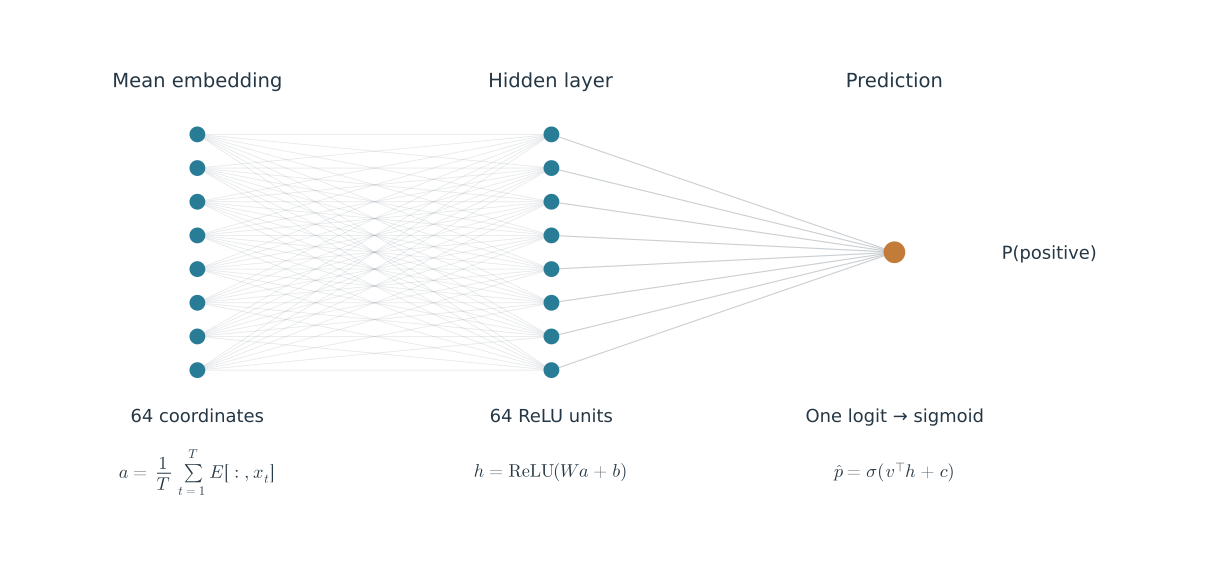

In [13]:
classifier_diagram()

*Figure 6. The actual classifier has 64 mean-embedding coordinates and 64 hidden units. Eight representative nodes per layer make the connections readable; all 64 coordinates participate in the computation. The mean, hidden-layer, and output formulas appear directly in the figure.*

### 2.6 Keep parameters and activations separate

| Object | Shape for one review | Role |
|---|---|---|
| $x_1,\ldots,x_T$, $y$ | $T$ IDs and one label | Observed data |
| $E$ | $64\times20{,}000$ | Trainable vocabulary embedding table |
| $W,b$ | $64\times64$, $64$ | Trainable hidden-layer weights and biases |
| $v,c$ | $64$, scalar | Trainable output weights and bias |
| $H,a,u,h,z,\hat p$ | As defined above | Activations recomputed for this input |

The complete parameter collection is $\theta=(E,W,b,v,c)$, with

$$\underbrace{64(20{,}000)}_{E}
+\underbrace{64(64)}_W+\underbrace{64}_b+\underbrace{64}_v+\underbrace{1}_c
=1{,}284{,}225\text{ parameters}.$$

The forward pass reads $\theta$ and produces activations. It does not change the parameters.

## 3. From prediction error to parameter updates

### 3.1 Define a loss for one observed review

For label $y\in\{0,1\}$ and predicted probability $\hat p$, define binary cross-entropy:

$$L(\theta;s,y)=-y\log\hat p-(1-y)\log(1-\hat p)
=\begin{cases}-\log\hat p&y=1,\\-\log(1-\hat p)&y=0.\end{cases}$$

The loss is small when the model assigns high probability to the observed label.
It becomes large when the prediction is confidently wrong.
The code uses the equivalent, numerically stable loss computed directly from logits.

In [14]:
L_review=review_loss(classifier_initial,trace_f,trace_target)
manual_L=-only(trace_target)*log(only(trace.p))-(1-only(trace_target))*log1p(-only(trace.p))
@assert isapprox(L_review,manual_L;atol=1f-6)
@printf("Observed y = %d; predicted p = %.6f; cross-entropy = %.6f\n",
    trace_row.y,only(trace.p),L_review)

Observed y = 0; predicted p = 0.500631; cross-entropy = 0.694410


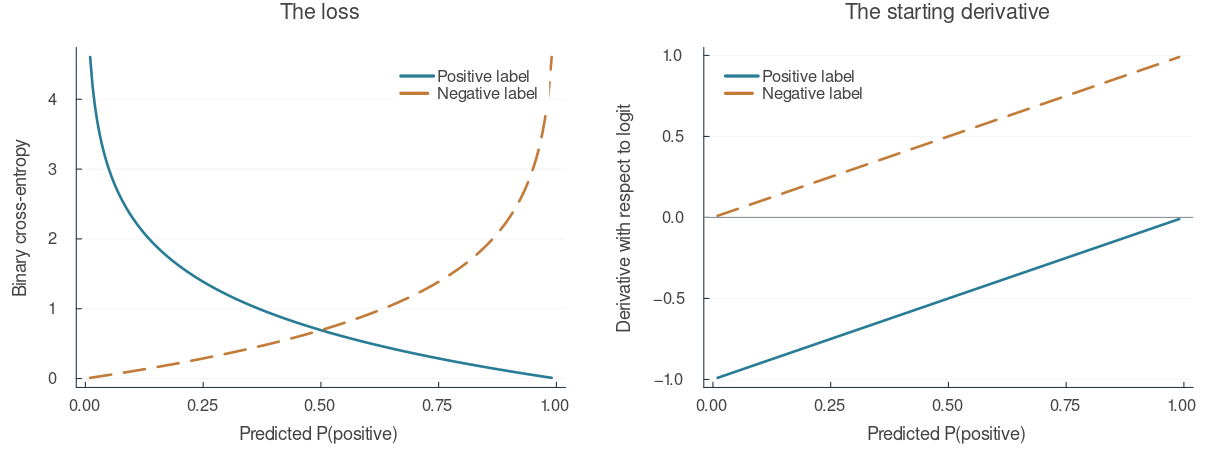

In [15]:
loss_plot()

*Figure 7. Left: how the probability affects cross-entropy. Right: the derivative with respect to the logit, derived next. The horizontal axis in both panels is the predicted probability.*

### 3.2 Draw the computation graph

The forward pass is a chain of simple operations. Backpropagation walks the same chain in reverse,
multiplying local derivatives. Figure 8 shows both directions; the next subsections derive each
backward label, and the code checks every one against automatic differentiation.

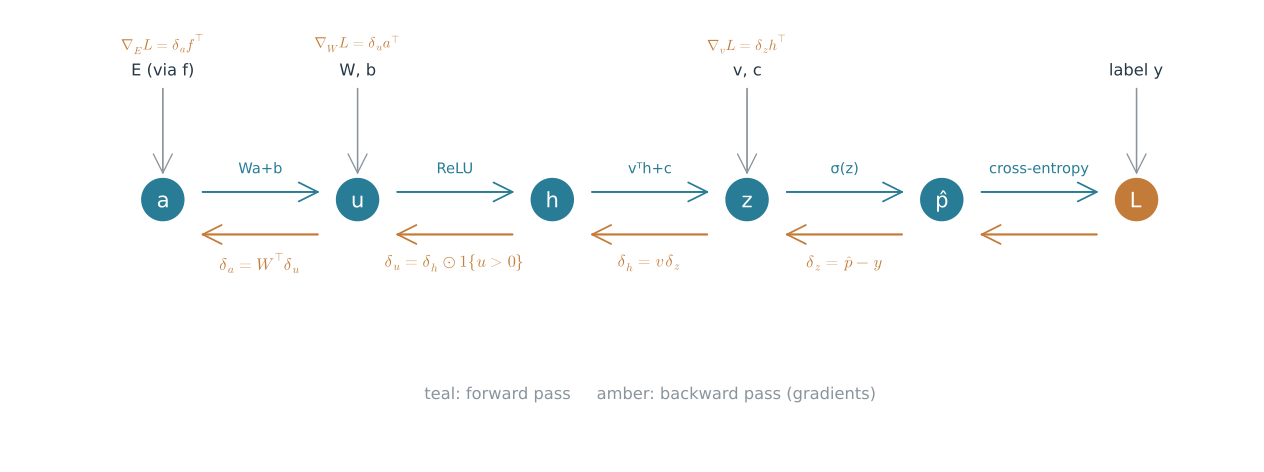

In [16]:
backprop_diagram()

*Figure 8. Forward pass (teal, left to right) and backward pass (amber, right to left). Each backward label multiplies the incoming gradient by a local derivative; parameter gradients (top) branch off the chain.*

### 3.3 Differentiate the output, without skipping the sigmoid

For an intermediate vector $q$, write $\delta_q=\partial L/\partial q$.
Begin with the two scalar derivatives:

$$\frac{\partial L}{\partial\hat p}
=-\frac{y}{\hat p}+\frac{1-y}{1-\hat p},
\qquad
\frac{\partial\hat p}{\partial z}=\hat p(1-\hat p).$$

The chain rule gives

$$\delta_z=\frac{\partial L}{\partial z}
=\left(-\frac{y}{\hat p}+\frac{1-y}{1-\hat p}\right)\hat p(1-\hat p)
=-y(1-\hat p)+(1-y)\hat p
=\hat p-y.$$

For a positive review, $\delta_z<0$, so a small descent step on $z$ would raise it.
For a negative review, $\delta_z>0$, so descent would lower it.
The optimizer actually changes parameters; the derivatives below tell it how each parameter affects $z$.

### 3.4 Continue backward through the output and hidden layer

Since $z=\sum_k v_kh_k+c$,

$$\frac{\partial L}{\partial v_k}=\delta_z h_k,\qquad
  \frac{\partial L}{\partial c}=\delta_z,\qquad
  (\delta_h)_k=\delta_z v_k.$$

For ReLU, a positive pre-activation has derivative 1 and a negative one has derivative 0.
We use derivative 0 at its kink, $u_k=0$. Therefore

$$\delta_u=\delta_h\odot\mathbf1_{\{u>0\}},$$

where $\odot$ means coordinate-by-coordinate multiplication.
Using $u_k=\sum_r W_{kr}a_r+b_k$, each derivative is

$$\frac{\partial L}{\partial W_{kr}}=(\delta_u)_k a_r,\qquad
  \frac{\partial L}{\partial b_k}=(\delta_u)_k,\qquad
  (\delta_a)_r=\sum_{k=1}^{64}W_{kr}(\delta_u)_k.$$

In matrix form:

$$\nabla_W L=\delta_u a^\top,\qquad
  \nabla_b L=\delta_u,\qquad
  \delta_a=W^\top\delta_u.$$

### 3.5 Continue through the average to the embedding table

Recall the exact scalar mean $a_r=\sum_j f_jE_{rj}$.
The frequencies $f_j$ are fixed for this review, so

$$\frac{\partial a_r}{\partial E_{rj}}=f_j=\frac{n_j}{T},\qquad
  \frac{\partial L}{\partial E_{rj}}=(\delta_a)_r\frac{n_j}{T}.$$

Across all coordinates and vocabulary entries,

$$\nabla_E L=\delta_a f^\top\in\mathbb R^{64\times20{,}000},
  \qquad \nabla_{E[:,j]}L=\frac{n_j}{T}\delta_a.$$

An unused word has $n_j=0$, hence zero gradient for this review.
A repeated word contributes through every occurrence.
Even a neutral word can move after one example; learning across many reviews separates
predictive patterns from incidental co-occurrence.
**There is no target embedding to copy. The prediction loss supplies its training signal.**

### 3.6 Apply one simultaneous parameter update

Let $\eta>0$ be the learning rate. Plain gradient descent applies

$$\theta_{\mathrm{new}}=\theta_{\mathrm{old}}
  -\eta\nabla_\theta L(\theta_{\mathrm{old}}).$$

For one embedding entry, this is explicitly

$$E_{rj}^{\mathrm{new}}
=E_{rj}^{\mathrm{old}}
-\eta\left[\frac{n_j}{T}(\delta_a)_r\right]_{\theta=\theta_{\mathrm{old}}}.$$

All derivatives are computed using the **old** parameters before any are updated.
Backpropagation computes gradients; the optimizer uses them to update parameters.
Activations such as $a$ and $h$ are recomputed on the next forward pass, not stored as learned parameters.

The cell below calculates every derivative by hand, checks it against Flux automatic
differentiation on the full model, and prints the actual numbers for one embedding update.
It leaves the original initialization intact for the training experiment.

Manual / AD maximum difference: 0.00e+00
One step on the full model: loss 0.694410 → 0.657733
Token 'the', ID 2, occurs 9/115 times


E[7,2]: 0.0094454 − 0.1 × (0.0099652) = 0.0084489
19920 unused vocabulary entries have exactly zero embedding gradient for this review.


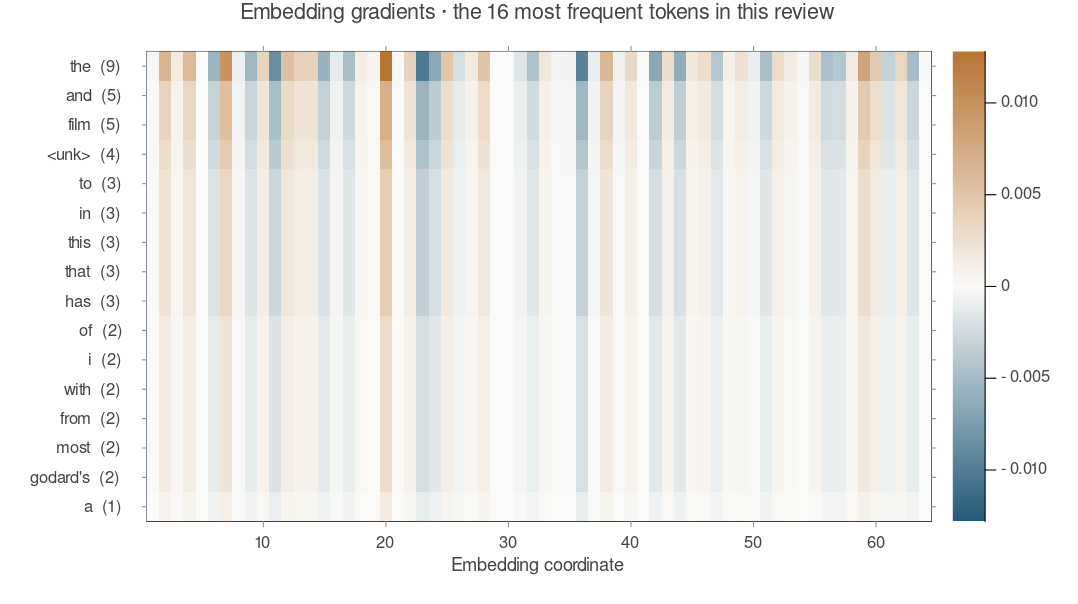

In [17]:
delta_z=trace.p-trace_target
delta_h=classifier_initial.v'*delta_z
delta_u=delta_h.*(trace.u.>0)
delta_a=classifier_initial.W'*delta_u
manual_gradient=(E=Matrix(delta_a*trace_f'),W=delta_u*trace.a',
    b=vec(delta_u),v=delta_z*trace.h',c=vec(delta_z))
ad_gradient=Flux.gradient(m->review_loss(m,trace_f,trace_target),classifier_initial)[1]
gradient_error=maximum(maximum(abs.(getproperty(manual_gradient,k).-getproperty(ad_gradient,k)))
    for k in keys(classifier_initial))
@assert gradient_error<2f-6
unused=setdiff(1:V_review,trace_ids)
@assert all(iszero,ad_gradient.E[:,unused])
eta=0.1f0
one_step=map((p,g)->p.-eta.*g,classifier_initial,ad_gradient)
@assert review_loss(one_step,trace_f,trace_target)<L_review
word_counts=Dict(j=>count(==(j),trace_ids) for j in unique(trace_ids))
gradient_ids=sort(collect(keys(word_counts));by=j->(-word_counts[j],j))[1:16]
focus_id=first(gradient_ids);r=7
@printf("Manual / AD maximum difference: %.2e\n",gradient_error)
@printf("One step on the full model: loss %.6f → %.6f\n",
    L_review,review_loss(one_step,trace_f,trace_target))
@printf("Token '%s', ID %d, occurs %d/%d times\n",
    imdb.vocab[focus_id],focus_id,word_counts[focus_id],T_review)
@printf("E[7,%d]: %.7f − %.1f × (%.7f) = %.7f\n",
    focus_id,classifier_initial.E[r,focus_id],eta,ad_gradient.E[r,focus_id],one_step.E[r,focus_id])
@printf("%d unused vocabulary entries have exactly zero embedding gradient for this review.\n",length(unused))
gradient_labels=[string(imdb.vocab[j],"  (",word_counts[j],")") for j in gradient_ids]
matrix_panel(ad_gradient.E[:,gradient_ids]';rowlabels=gradient_labels,
    title="Embedding gradients · the 16 most frequent tokens in this review",
    xlabel="Embedding coordinate") |> p->plot(p;size=(980,550))

*Figure 9. A real review produces gradients in the full 64 × 20,000 table. The displayed rows are its 16 most frequent vocabulary IDs; parentheses give occurrence counts. Repeated words receive proportionally larger contributions. The code also verifies zero gradients for every unused entry.*

## 4. Train and evaluate the IMDb network

### 4.1 Average gradients across a batch

For a batch $\mathcal B$ of $B$ reviews, the objective and its derivative are

$$L_{\mathcal B}(\theta)=\frac1B\sum_{n\in\mathcal B}L(\theta;s_n,y_n),
\qquad
\nabla_\theta L_{\mathcal B}=\frac1B\sum_{n\in\mathcal B}\nabla_\theta L_n.$$

**Mini-batches and epochs.** Let $N=22{,}411$ be the number of training reviews and $B=128$ the batch size.
At the start of every epoch the training loop

1. draws a random permutation of the $N$ training reviews;
2. cuts it into consecutive blocks of $B$ reviews (the last block holds the remainder);
3. for each block in turn, computes $L_{\mathcal B}$ and its gradient, and **updates the parameters once**.

| Quantity | Value |
|---|---|
| Training reviews $N$ | 22,411 |
| Batch size $B$ | 128 |
| Updates (mini-batches) per epoch | $\lceil N/B\rceil=176$: 175 blocks of 128 and one of 11 |
| Epochs | 8 |
| Total updates | $176\times8=1{,}408$ here; $176\times10=1{,}760$ for the RNNs; $176\times6=1{,}056$ for the LSTM |

An **epoch** is one full pass over the training data, not one update: the parameters change 176 times per epoch,
each time using the mean loss of one batch. Three choices of batch size span the possibilities:

| Method | Reviews per update | Updates per epoch |
|---|---|---|
| Full-batch gradient descent | 22,411 | 1 |
| Mini-batch gradient descent (this notebook) | 128 | 176 |
| Stochastic gradient descent with one review | 1 | 22,411 |

Each batch is a uniformly random subset of the training reviews, so its gradient $\nabla_\theta L_{\mathcal B}$ is an
unbiased estimate of the full-data gradient, at $1/175$ of the cost. Many cheap, noisy steps make more progress per pass
than one exact step. The noise is visible in the faint per-update curve of Figure 10.

**Why sample without replacement?** Shuffling once per epoch and cutting into blocks is sampling *without* replacement:
every review is used exactly once per epoch, and once in every later epoch, eight times in total.
Sampling *with* replacement would also give unbiased batch gradients, but $N$ independent draws would miss a fraction
$(1-1/N)^N\approx e^{-1}\approx37\%$ of the reviews and use others two or more times.
Reshuffling avoids this imbalance, is the default in deep-learning libraries, and usually converges slightly faster.

We use Adam instead of plain gradient descent for the full fit. For update index $q$ and
batch gradient $g_q$, Adam keeps two running arrays, initially $m_0=v_0=0$:

$$m_q=\beta_1m_{q-1}+(1-\beta_1)g_q,\qquad
  v_q=\beta_2v_{q-1}+(1-\beta_2)(g_q\odot g_q).$$

With bias correction $\hat m_q=m_q/(1-\beta_1^q)$ and
$\hat v_q=v_q/(1-\beta_2^q)$, its update is

$$\theta_q=\theta_{q-1}
-\eta\frac{\hat m_q}{\sqrt{\hat v_q}+\epsilon}.$$

All operations in this update are coordinatewise; $\beta_1,\beta_2\in[0,1)$ control smoothing
and $\epsilon>0$ stabilizes the denominator. These optimizer arrays are distinct from the
classifier's output vector $v$. Adam changes the update rule, not the forward equations or chain rule.

### 4.2 Fit the same 1.28-million-parameter model

The fit starts from the exact initialization used above.
It uses eight epochs, learning rate 0.003, and all tokenized words in every review.
After each epoch, validation cross-entropy determines whether to keep that checkpoint.
Only after selection is the test set evaluated.

`TRAIN_SENTIMENT=true` retrains the model; false loads its saved result.
The ten-minute fit budget is checked between updates; setup and final evaluation add time.

In [18]:
TRAIN_SENTIMENT=true
sentiment=TRAIN_SENTIMENT ? train_reviews(imdb,classifier_initial) : deserialize(joinpath(RESULTS,"sentiment.jls"))
@assert sentiment.vocab==imdb.vocab
@assert sentiment.initial==classifier_initial
TRAIN_SENTIMENT && serialize(joinpath(RESULTS,"sentiment.jls"),sentiment)
@printf("%s parameters | selected epoch %d | fit %.1f seconds\n",
    string(sum(length,values(sentiment.model))),sentiment.best_epoch,sentiment.seconds)

Epoch 1 | train 0.178 | validation 0.263 | val accuracy 89.2% | 4 s


Epoch 2 | train 0.106 | validation 0.268 | val accuracy 89.4% | 5 s


Epoch 3 | train 0.056 | validation 0.294 | val accuracy 89.0% | 6 s


Epoch 4 | train 0.038 | validation 0.361 | val accuracy 88.8% | 8 s


Epoch 5 | train 0.021 | validation 0.450 | val accuracy 87.4% | 9 s


Epoch 6 | train 0.007 | validation 0.505 | val accuracy 88.1% | 11 s


Epoch 7 | train 0.003 | validation 0.581 | val accuracy 88.0% | 12 s


Epoch 8 | train 0.002 | validation 0.623 | val accuracy 88.1% | 13 s


1284225 parameters | selected epoch 1 | fit 13.5 seconds



The training run also logged the loss at a finer resolution, as is usual in deep learning:

- **Training loss of every mini-batch**, computed just before its update. It costs nothing extra,
  because the gradient needs it anyway, but it is noisy: every batch contains 128 different reviews.
  A moving average shows the trend.
- **Validation loss every 20 updates**, on all 2,490 validation reviews.

Figure 10 shows the run at both resolutions: after every epoch (left and middle) and after every update (right).


176 updates per epoch × 8 epochs = 1408 updates | validation every 20 updates
  update    1: mini-batch loss 0.693
  update   20: mini-batch loss 0.671
  update   50: mini-batch loss 0.481
  update  100: mini-batch loss 0.239
  update  176: mini-batch loss 0.405
  update  352: mini-batch loss 0.272


  update 1408: mini-batch loss 0.002
Lowest validation loss among the checks: 0.256 after update 340 (1.93 epochs)


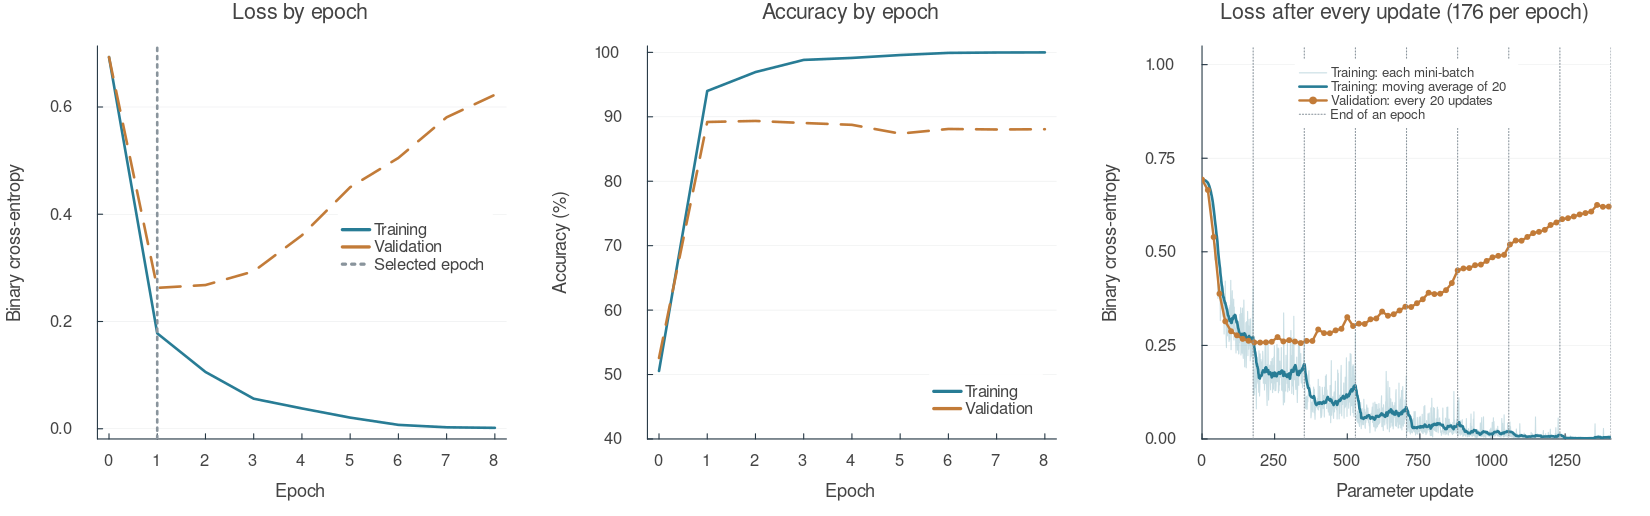

In [19]:

per=sentiment.updates_per_epoch
n_updates=length(sentiment.steps.step)
@printf("%d updates per epoch × %d epochs = %d updates | validation every %d updates\n",
    per,length(sentiment.history)-1,n_updates,sentiment.config.eval_every)
for k in (1,20,50,100,per,2per,n_updates)
    @printf("  update %4d: mini-batch loss %.3f\n",k,sentiment.steps.batch_loss[k])
end
bc=sentiment.checks[argmin([c.val_loss for c in sentiment.checks])]
@printf("Lowest validation loss among the checks: %.3f after update %d (%.2f epochs)\n",
    bc.val_loss,bc.step,bc.step/per)
training_plot(sentiment)


*Figure 10. One training run at two resolutions. Left and middle: loss and accuracy on all training and validation reviews after every epoch; the dotted line marks the selected epoch. Right: the loss of each mini-batch (faint), its moving average (dark), and validation loss every 20 updates (amber), against the number of parameter updates; dotted lines mark the ends of epochs.*

**Why does validation loss rise while validation accuracy barely moves?**
Between epochs 1 and 8, validation accuracy only falls from 89.2% to 88.1%, but validation loss
more than doubles, from 0.263 to 0.623. The two metrics measure different things:

- Accuracy only asks whether $\hat p_n$ is on the correct side of 0.5.
- Cross-entropy also asks **how confident** the prediction is: a wrong prediction made with
  $\hat p_n=0.999$ costs $-\log(0.001)\approx6.9$, about ten times the cost of a hesitant mistake.

As training continues, the network memorizes the training reviews and becomes extremely confident
on every review. The validation reviews it gets wrong are about as many as before,
but they are now wrong with near-certainty, so their losses, and the average, grow quickly.

The right panel shows three things that the epoch view hides:

1. **Most learning happens in the first 100 updates.** The mini-batch loss falls from 0.693
   (the random guess) to about 0.24 by update 100, before the model has seen even 60% of the
   training reviews once.
2. **The training loss drops in steps at every epoch boundary.** From update 177 on, the model
   sees reviews it has already been trained on, and their loss is immediately lower.
   This is memorization: the step appears in the training curve but not in the validation curve.
3. **Validation loss is flat between about updates 180 and 360, then rises.** Its lowest check,
   0.256 after update 340, is close to the end of epoch 2; the epoch-level rule
   selected epoch 1 (0.263), a nearly identical model. Checking validation more often than once
   per epoch is how practitioners locate the stopping point more precisely.

### 4.3 Measure performance and inspect mistakes

Let $\hat y_n=\mathbf1\{\hat p_n\geq0.5\}$ and let $N_{\rm test}$ be the number of test reviews.

$$\mathrm{Accuracy}=\frac1{N_{\rm test}}\sum_n\mathbf1\{\hat y_n=y_n\}.$$

A **true positive** (TP) is a positive review predicted positive.
A **false positive** (FP) is a negative review predicted positive.
A **false negative** (FN) is a positive review predicted negative.
Positive-class F1 combines these counts:

$$F_1=\frac{2TP}{2TP+FP+FN}.$$

The confusion matrix uses actual labels in rows and predicted labels in columns.
We also compare accuracy with the majority-label rule selected from training labels.

Filtered test: 24675 reviews | accuracy 87.78% | positive F1 0.8730 | loss 0.2969


Training-majority baseline: 50.30%


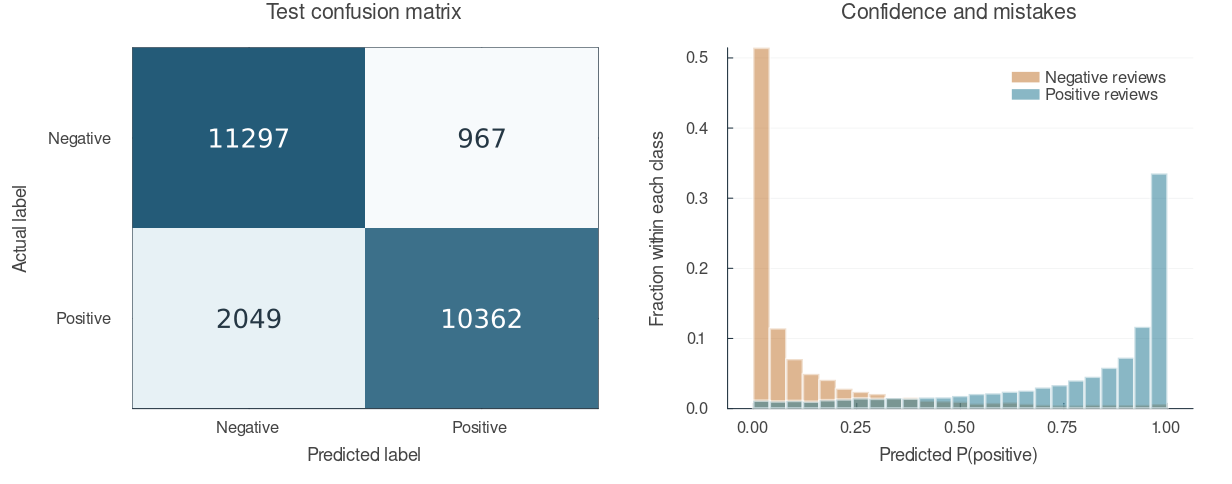

In [20]:
@printf("Filtered test: %d reviews | accuracy %.2f%% | positive F1 %.4f | loss %.4f\n",
    length(imdb.test.rows),100sentiment.test.accuracy,sentiment.test.f1,sentiment.test.loss)
majority=mean(imdb.training.y)>=0.5
@printf("Training-majority baseline: %.2f%%\n",100mean((vec(imdb.test.y).>=0.5).==majority))
test_plot(sentiment.test,imdb.test.y)

*Figure 11. The matrix reports counts. Each probability histogram is normalized within its actual class, making confident errors and ambiguous predictions visible.*

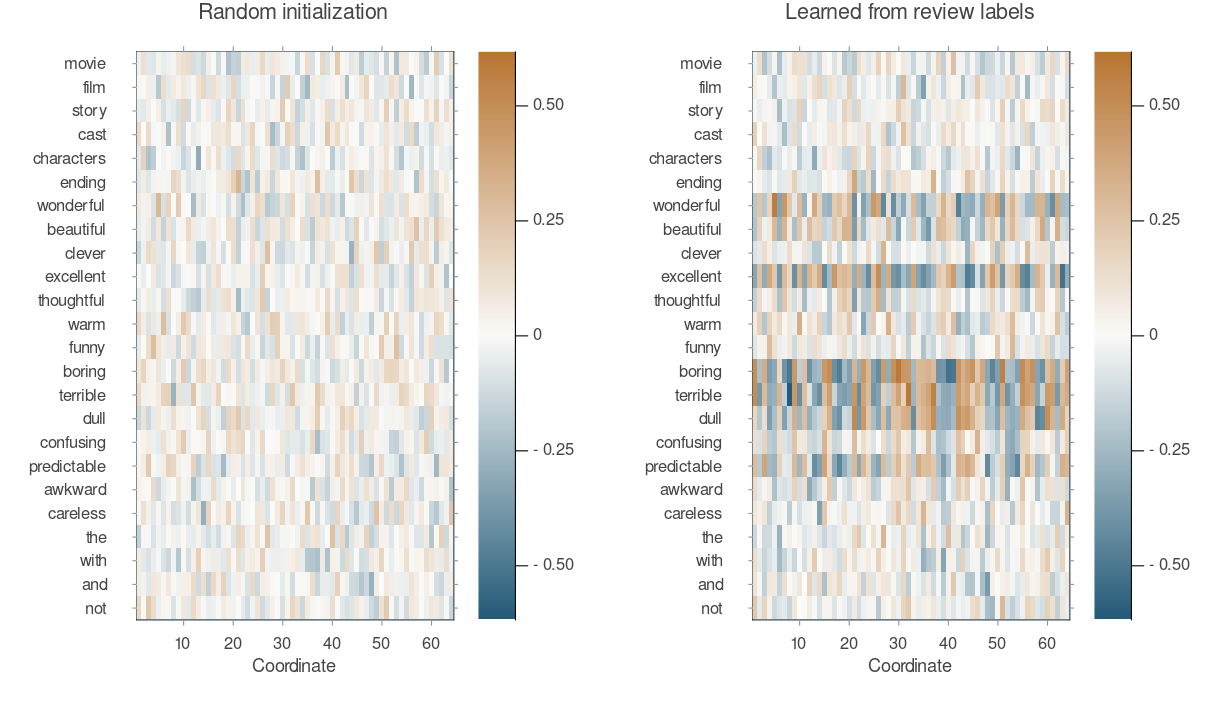

In [21]:
embedding_compare_plot(sentiment.initial.E,sentiment.model.E,shown_words,imdb.lookup)

*Figure 12. The same entries in the same full embedding table before and after fitting, with common color limits. All 64 coordinates are displayed.*

### 4.4 What did the word vectors learn?

Figure 12 compares the same table entries before and after fitting. Training changed $E$ only
through the sentiment loss, so the learned vectors encode whatever helps predict the label.
To read one word's learned vector, feed the network a "review" containing only word $j$.
Then $f=o_j$, $a=E o_j=e_j$, and the word's **single-word logit** is

$$s_j=v^\top\operatorname{ReLU}(We_j+b)+c.$$

Positive $s_j$ pushes a review toward "positive"; negative $s_j$ pushes it toward "negative".
We report words that appear in at least 100 training reviews, so that each estimate rests on many examples.

3524 frequent words; single-word logits range from -67.78 to 47.92


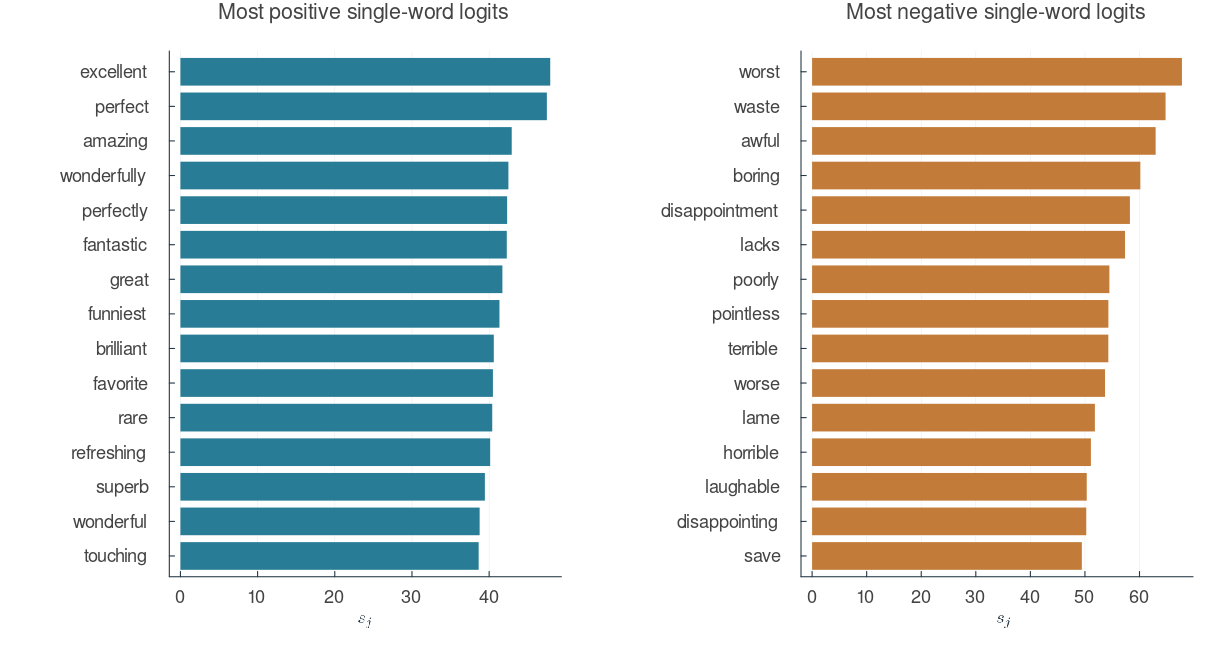

In [22]:
learned=sentiment.model
word_logit=single_word_logits(learned)
doc_freq=vec(sum(imdb.training.F .> 0;dims=2))
frequent=filter(j->j!=1 && doc_freq[j]>=100,1:V_review)
ranked=frequent[sortperm(word_logit[frequent])]
neg_ids,pos_ids=ranked[1:15],reverse(ranked[end-14:end])
@printf("%d frequent words; single-word logits range from %.2f to %.2f\n",
    length(frequent),word_logit[ranked[1]],word_logit[ranked[end]])
word_logit_plot(word_logit,pos_ids,neg_ids,imdb.vocab)

*Figure 13. Each bar is the trained network's logit for a review made of one word. No word was ever labeled; these scores come entirely from review-level labels and backpropagation through the mean.*

Words with similar roles should end up with similar vectors. Measure closeness with **cosine similarity**,

$$\cos(e_i,e_j)=\frac{e_i^\top e_j}{\lVert e_i\rVert\,\lVert e_j\rVert}\in[-1,1],$$

which compares directions and ignores lengths. The cell lists each probe word's nearest frequent
neighbours in the random initial table and in the learned table.

In [23]:
for w in ["excellent","awful","boring","beautiful","plot"]
    @printf("%-10s random : %s\n",w,join(nearest_words(sentiment.initial.E,w,imdb;candidates=frequent),", "))
    @printf("%-10s learned: %s\n\n",w,join(nearest_words(learned.E,w,imdb;candidates=frequent),", "))
end

excellent  random : episodes, eddie, exact, she, peter, levels


excellent  learned: perfectly, entertaining, perfect, great, favorite, best

awful      random : success, drags, won, rental, sequels, woods
awful      learned: worse, boring, stupid, waste, disappointment, poorly

boring     random : meanwhile, necessary, wayne, scares, revealed, stick
boring     learned: poorly, unless, awful, disappointment, waste, worse

beautiful  random : serious, bunch, stage, stretch, drunk, multiple
beautiful  learned: fantastic, wonderfully, touching, best, rare, eerie

plot       random : and, hour, bridge, problem, superficial, intense
plot       learned: problem, insult, badly, pointless, shoot, stiff



After training, sentiment words cluster with words of the same polarity, while the random
table's neighbours are arbitrary. Even `plot` now sits among negative words: in IMDb reviews,
complaints tend to discuss the plot, and the loss only rewards information about sentiment.
The vector does not describe what a plot *is*. This is a general principle: **an embedding learns what its training
objective needs**.

### 4.5 What averaging cannot represent

The two probe sentences `The movie is good, not bad` and `The movie is bad, not good`
have the same word counts. Therefore they have the same $f$, the same $a=Ef$,
and the same prediction, despite their different word order.
This is the bag-of-words property of the average. The code below verifies the equality and lists two test-set mistakes.

This is a limitation of this architecture, not a shortage of training epochs.
To model order and context, the model must combine the word vectors in a way that depends on their order.
Short probes also differ from the full reviews used in training; their probabilities are not calibrated guarantees.

In [24]:
my_reviews=["The actors were wonderful and the story kept me interested.",
    "The plot was confusing and the dialogue was painfully dull.",
    "The movie is good, not bad.","The movie is bad, not good."]
for s in my_reviews
    @printf("P(positive) = %.4f | %s\n",sentiment_probability(s,sentiment),s)
end
@assert sentiment_probability(my_reviews[3],sentiment)≈sentiment_probability(my_reviews[4],sentiment)
mistakes=findall((sentiment.test.probabilities.>=0.5).!=(vec(imdb.test.y).>=0.5))
println("\nFirst two errors in source order (short excerpts):")
for i in first(mistakes,2)
    @printf("label=%d, P(positive)=%.3f: %s…\n",imdb.test.rows[i].y,
        sentiment.test.probabilities[i],first(replace(imdb.test.rows[i].text,r"<[^>]*>"=>" "),130))
end

P(positive) = 0.9980 | The actors were wonderful and the story kept me interested.
P(positive) = 0.0000 | The plot was confusing and the dialogue was painfully dull.
P(positive) = 0.0003 | The movie is good, not bad.
P(positive) = 0.0003 | The movie is bad, not good.



First two errors in source order (short excerpts):
label=0, P(positive)=0.951: First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of th…


label=0, P(positive)=0.589: Blind Date (Columbia Pictures, 1934), was a decent film, but I have a few issues with this film. First of all, I don't fault the a…


## 5. Two experiments on the data

The model above is fitted on $n=22{,}411$ labelled reviews. Two questions:

1. **Quantity:** how does test accuracy change with the number of training reviews?
2. **Quality:** how does it change when some labels are wrong?

Each experiment changes only the training data. The model, starting values, training rules and test set stay fixed.
`RUN_EXPERIMENTS=true` refits (about 10 and 13 minutes); otherwise saved results are loaded.

In [25]:
RUN_EXPERIMENTS=false

false

### 5.1 Learning curve

Draw $m$ of the $n$ training reviews at random, fit the model, and record the test accuracy $\mathrm{Acc}(m)$.

- $m$ ranges from 112 to $n$ (13 sizes), with 3 random draws each.
- Same number of updates for every $m$: train for $8\,n/m$ epochs instead of 8, so we compare data, not training time.

Figure 14: horizontal axis $m$ (log scale); dots are draws, the line is their mean.

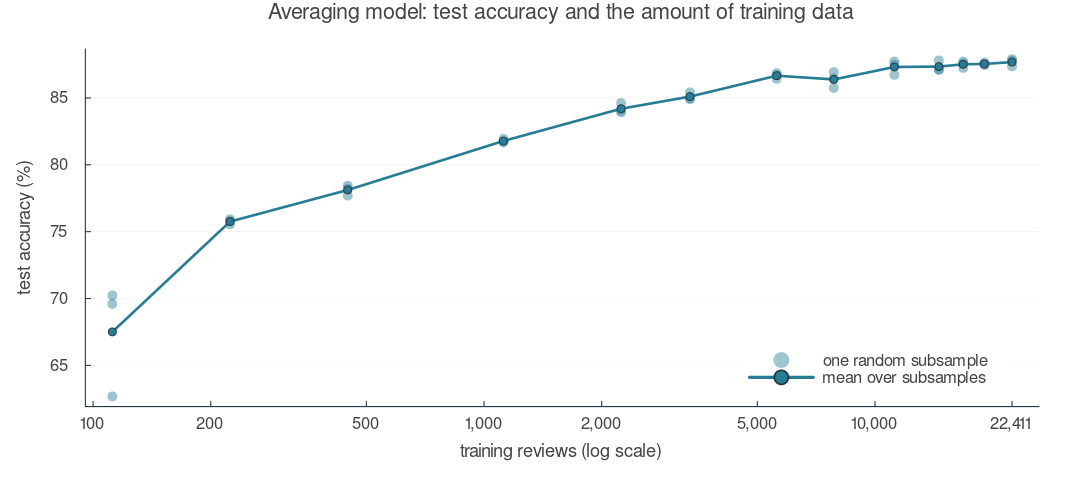

In [26]:
curve=experiment_or_load("learning_curve",()->learning_curve(imdb,classifier_initial),RESULTS;rerun=RUN_EXPERIMENTS)
learning_curve_plot(curve)

*Figure 14. Learning curve of the averaging model.*

- Small $m$: accuracy is low and depends on the draw. Most words never appear, so their vectors stay random.
- Between a few hundred and a few thousand reviews: roughly linear in $\log m$, so each doubling adds a similar gain.
- Above about 5,000 reviews: flat. The last doublings add less than the spread between draws.

So the averaging model is close to its limit at $n$. More data of the same kind would help little; the bottleneck is the model, which ignores word order.

### 5.2 Label noise

Flip a random share $\rho$ of the training labels:

$$
\tilde y_i=\begin{cases}1-y_i&\text{with probability }\rho,\\ y_i&\text{otherwise,}\end{cases}
\qquad \rho\in\{0,0.05,0.1,0.2,0.3,0.4,0.45,0.5\}.
$$

Fit the model on $\tilde y$ and evaluate it on the **true** test labels. $\rho=0$ is the baseline, the model fitted above; $\rho=0.5$ makes labels pure coin flips.

**Prediction.** With $p(x)=P(y=1\mid x)$, the noisy label satisfies

$$
\tilde p(x)=P(\tilde y=1\mid x)=\rho+(1-2\rho)\,p(x)
\quad\Longrightarrow\quad
\tilde p(x)-\tfrac12=(1-2\rho)\big(p(x)-\tfrac12\big).
$$

1. Same sign: for $\rho<\tfrac12$ the best classifier is unchanged, so with unlimited data accuracy would not fall.
2. Predictions shrink toward $\tfrac12$ by the factor $1-2\rho$.
3. The signal per label shrinks by $1-2\rho$, so $n$ noisy labels are worth about $n_{\text{eff}}=n(1-2\rho)^2$ clean ones.

**Three lines in Figure 15.** The model is saved every 20 updates; each line keeps one saved model.

| Line | Training labels | Stop on validation labels | Compares |
|---|---|---|---|
| (a) realistic | $\tilde y$ | $\tilde y$ | |
| (b) benchmark | $\tilde y$ | $y$ (true) | (a) vs (b): cost of noisy validation |
| (c) control | $y$, only $n_{\text{eff}}$ reviews | $y$ | (a) vs (c): is noise just less data? |

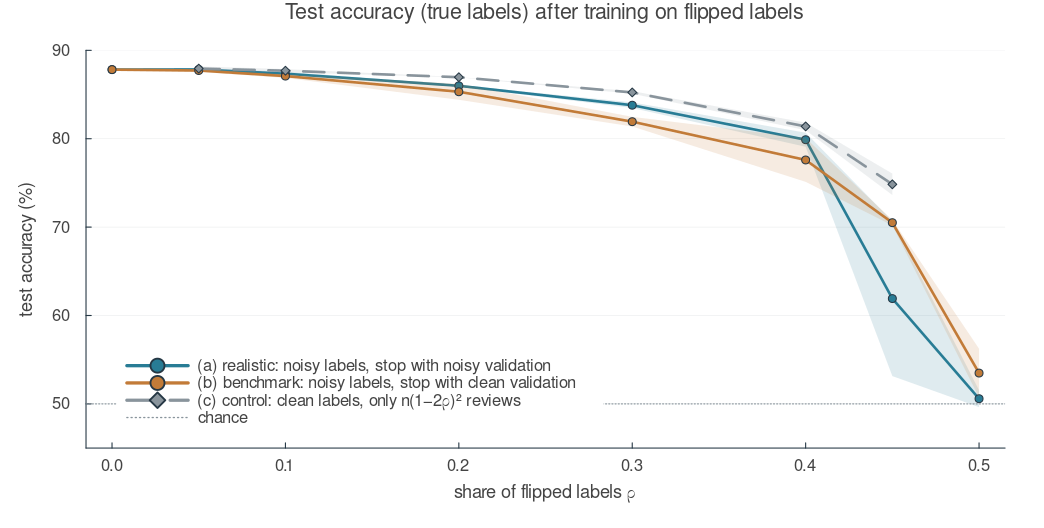

In [27]:
noise=experiment_or_load("label_noise",()->label_noise_experiment(imdb,classifier_initial),RESULTS;rerun=RUN_EXPERIMENTS)
label_noise_plot(noise;panel=:accuracy)

*Figure 15. Test accuracy (true labels) against $\rho$; mean over 3 draws, band ± one standard deviation.*

- (a) stays near the baseline up to $\rho\approx0.1$, loses a few points at 0.2–0.3, and falls to 50% between 0.4 and 0.5 (prediction 1, until the signal is gone).
- (c) is above (a) everywhere: noise costs a bit more than losing data.
- (b) is *below* (a) up to 0.4. Noisy-trained predictions sit near $\tfrac12$ (prediction 2), which the true-label loss penalizes, so (b) stops later, after more memorization.

**Inside the selected model (rule a).** Two measures, both in $[0,1]$. Let $\mathcal F$ be the flipped training reviews and $\hat y_i=\mathbb 1\{\hat p_i>\tfrac12\}$:

$$
\text{wrong labels learned}=\frac{1}{|\mathcal F|}\sum_{i\in\mathcal F}\mathbb 1\{\hat y_i=\tilde y_i\},
\qquad
\text{confidence}=\frac{2}{N}\sum_{i\in\text{test}}\big|\hat p_i-\tfrac12\big|.
$$

- Wrong labels learned: without any memorization it equals the model's ordinary error rate (about 0.12), not 0.
- Confidence: 1 if $\hat p\in\{0,1\}$, 0 if $\hat p=\tfrac12$. Dashed line: prediction 2, $(1-2\rho)\times$ confidence at $\rho=0$.

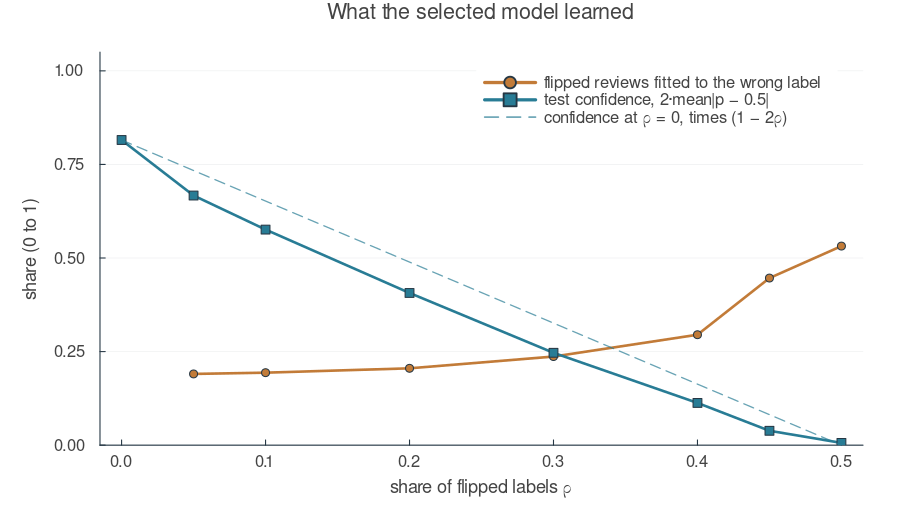

In [28]:
label_noise_plot(noise;panel=:learned)

*Figure 16. Wrong labels learned (amber) and confidence (teal; dashed: prediction 2), against $\rho$.*

- Confidence follows prediction 2, slightly below it: the model becomes less sure, not more wrong.
- Wrong labels learned stays near the ordinary error rate up to $\rho\approx0.2$, then rises steeply: at high noise the model memorizes. This is the gap between (a) and (c).

### 5.3 Summary

- More data of the same kind would barely help the averaging model.
- Symmetric label noise mainly lowers confidence; accuracy drops only when noise is large.
- Stopping on true-label validation loss can select a model that has memorized more noise.